# Unemployment in India: Regional and COVID-19 Trends
### Exploratory analysis of the supplied monthly survey data

This notebook combines the two supplied CSVs, standardizes their shared fields, and examines regional and temporal variation. The files are observational survey estimates, and the period around 2020 should be read as a before/after comparison, not a causal estimate of the pandemic?s effect.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
sns.set_theme(style='whitegrid', palette='colorblind')
DATA_DIR = Path('.')

In [2]:
# Use the area-level file as the primary source: the second CSV is state-level and has a different grain.
a = pd.read_csv(DATA_DIR / 'Unemployment in India.csv')
a.columns = [str(c).strip() for c in a.columns]
rename = {'Estimated Unemployment Rate (%)':'unemployment_rate','Estimated Employed':'employed','Estimated Labour Participation Rate (%)':'labour_participation_rate','Region':'region','Date':'date','Frequency':'frequency','Area':'area'}
df = a.rename(columns=rename).copy()
print('Primary file shape:',df.shape)
for c in ['unemployment_rate','employed','labour_participation_rate']:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',','',regex=False).str.strip(), errors='coerce')
df['region'] = df['region'].astype('string').str.strip().str.title()
df['area'] = df['area'].astype('string').str.strip().str.title()
df['date'] = pd.to_datetime(df['date'].astype(str).str.strip(), dayfirst=True, errors='coerce')
df = df.dropna(subset=['region','date']).drop_duplicates(subset=['region','date','area'],keep='first').sort_values('date')
print('Cleaned shape:',df.shape,'| Date range:',df.date.min().date(),'to',df.date.max().date())
display(df.head())
print('Dtypes:'); print(df.dtypes)
print('Missing values:'); print(df.isna().sum())
display(df[['unemployment_rate','employed','labour_participation_rate']].describe().T)

Primary file shape: (768, 7)
Cleaned shape: (740, 7) | Date range: 2019-05-31 to 2020-06-30


,region,date,frequency,unemployment_rate,employed,labour_participation_rate,area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
290,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
276,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
257,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
243,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


Dtypes:
region                               string
date                         datetime64[us]
frequency                               str
unemployment_rate                   float64
employed                            float64
labour_participation_rate           float64
area                                 string
dtype: object
Missing values:
region                       0
date                         0
frequency                    0
unemployment_rate            0
employed                     0
labour_participation_rate    0
area                         0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
unemployment_rate,740.0,1.178795e+01,1.072130e+01,0.00,4.657500e+00,8.35,1.588750e+01,76.74
employed,740.0,7.204460e+06,8.087988e+06,49420.00,1.190404e+06,4744178.50,1.127549e+07,45777509.00
labour_participation_rate,740.0,4.263012e+01,8.111094e+00,13.33,3.806250e+01,41.16,4.550500e+01,72.57


### Regional averages and monthly pattern
Each row is an area-level estimate. The regional averages below weight each available row equally; different counts of area observations can affect comparability. The time-series chart averages areas within each state and month.

,mean,median,count
region,,,
Tripura,28.35,27.31,28
Haryana,26.28,25.06,28
Jharkhand,20.58,17.28,28
Bihar,18.92,15.01,28
Himachal Pradesh,18.54,18.35,28
Delhi,16.50,15.02,28
Jammu & Kashmir,16.19,16.00,21
Chandigarh,15.99,17.51,12
Rajasthan,14.06,13.66,28


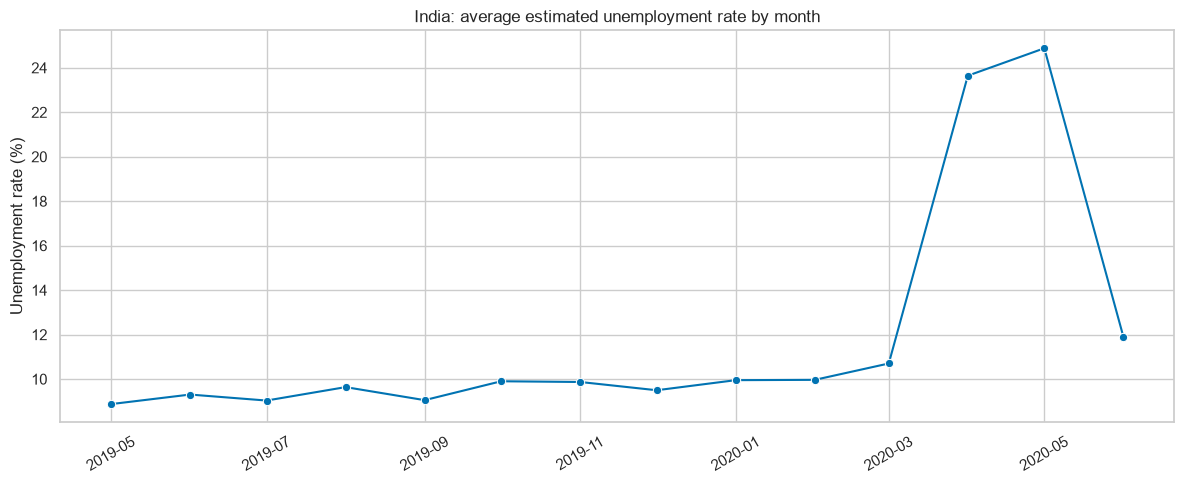

In [3]:
region_avg = df.groupby('region', observed=True)['unemployment_rate'].agg(['mean','median','count']).sort_values('mean',ascending=False)
display(region_avg.round(2))
monthly = df.groupby(df['date'].dt.to_period('M'))['unemployment_rate'].mean().reset_index()
monthly['date'] = monthly['date'].dt.to_timestamp()
fig, ax = plt.subplots(figsize=(12,5)); sns.lineplot(data=monthly,x='date',y='unemployment_rate',marker='o',ax=ax)
ax.set(title='India: average estimated unemployment rate by month',xlabel='',ylabel='Unemployment rate (%)'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

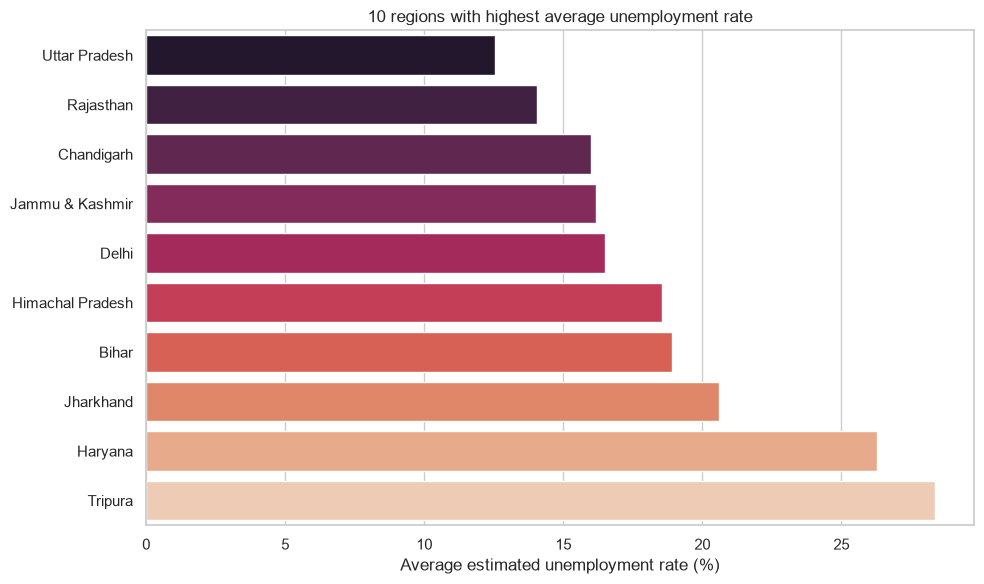

In [4]:
top10 = region_avg.head(10).sort_values('mean')
fig, ax = plt.subplots(figsize=(10,6)); sns.barplot(x=top10['mean'],y=top10.index,ax=ax,palette='rocket')
ax.set(title='10 regions with highest average unemployment rate',xlabel='Average estimated unemployment rate (%)',ylabel=''); plt.tight_layout(); plt.show()

### State trends and relationships
The three most frequently observed regions are selected to avoid choosing states only because they have high rates. The heatmap is descriptive: employment and participation estimates have different scales and may move together because of survey construction.

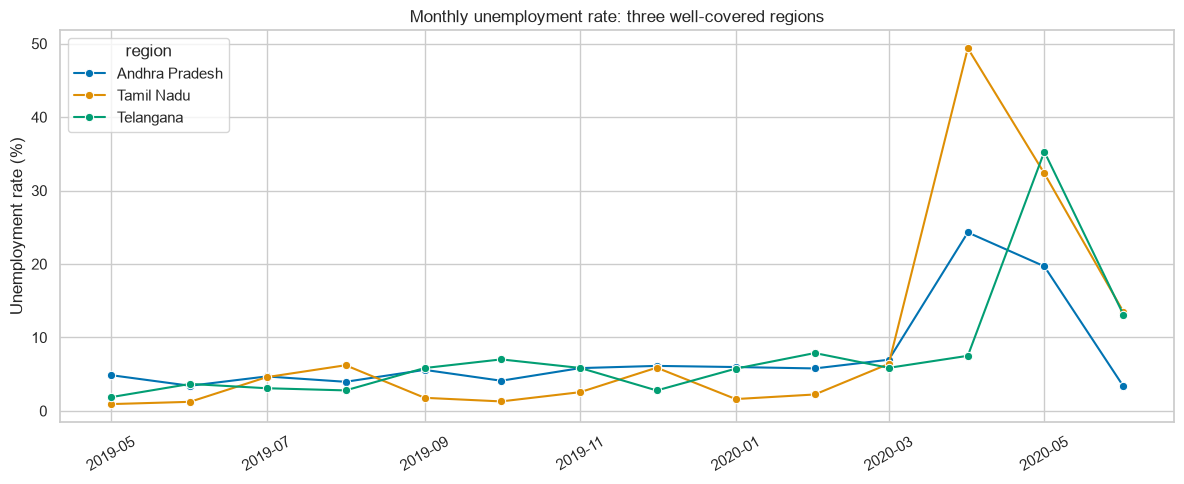

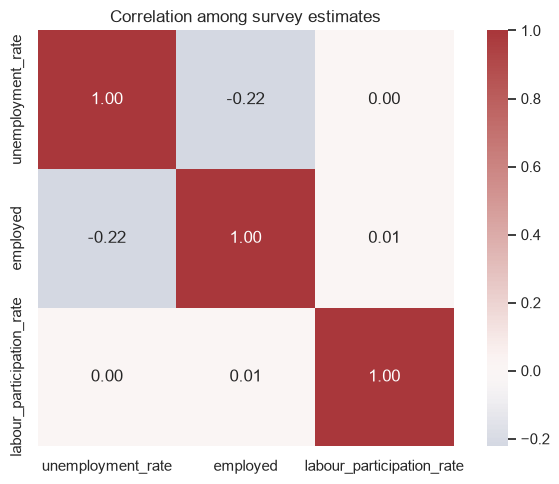

In [5]:
top_regions = df['region'].value_counts().head(3).index.tolist()
state_month = df[df.region.isin(top_regions)].groupby(['region',df.date.dt.to_period('M')],observed=True)['unemployment_rate'].mean().reset_index()
state_month['date'] = state_month['date'].dt.to_timestamp()
fig, ax = plt.subplots(figsize=(12,5)); sns.lineplot(data=state_month,x='date',y='unemployment_rate',hue='region',marker='o',ax=ax)
ax.set(title='Monthly unemployment rate: three well-covered regions',xlabel='',ylabel='Unemployment rate (%)'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
cols=['unemployment_rate','employed','labour_participation_rate']
plt.figure(figsize=(7,5)); sns.heatmap(df[cols].corr(),annot=True,cmap='vlag',center=0,fmt='.2f',square=True)
plt.title('Correlation among survey estimates'); plt.tight_layout(); plt.show()

### Before and after the pandemic onset
For a transparent descriptive split, this notebook uses 1 March 2020 as the start of the post-onset period. The table compares row-level means and medians. The time windows are unequal and the values are survey estimates; the difference cannot isolate COVID-19 from seasonality, other economic events, or measurement changes.

In [6]:
df['period'] = np.where(df['date'] < pd.Timestamp('2020-03-01'),'Pre-COVID (before Mar 2020)','Post-onset (Mar 2020 onward)')
comparison = df.groupby('period',observed=True).agg(unemployment_mean=('unemployment_rate','mean'),unemployment_median=('unemployment_rate','median'),labour_participation_mean=('labour_participation_rate','mean'),employed_mean=('employed','mean'),observations=('unemployment_rate','count'))
display(comparison.round(2))

,unemployment_mean,unemployment_median,labour_participation_mean,employed_mean,observations
period,,,,,
Post-onset (Mar 2020 onward),17.77,14.52,39.33,6517203.34,204
Pre-COVID (before Mar 2020),9.51,7.12,43.89,7466027.87,536


## Key observations
Review the plots and comparison table after running the notebook. Look for the sharpest monthly movements, whether the three state trajectories rise and fall at the same time, and how regional averages vary. The COVID comparison is an association across two periods, not a causal estimate. The two source files overlap, so duplicate removal at region/date/area grain is important to avoid counting shared observations twice.